**Bahasa Indonesia**

# 01 — Superdense coding: teori, diagram, dan pengukuran

**Quantum Chat 0.1.1 · research preview · MIT · Python 3.12.**

Notebook ini menurunkan alur dua bit → satu qubit yang dikirim setelah satu
pasangan Bell dibagikan, lalu memeriksa empat simbol memakai engine proyek.
Ini simulasi lokal, bukan pengiriman qubit fisik atau komunikasi instan.
Jalankan seluruh cell berurutan pada environment repository.

---

**English**

# 01 — Superdense coding: theory, diagrams, and measurements

**Quantum Chat 0.1.1 · research preview · MIT · Python 3.12.**

This notebook derives the two-bit → one-transmitted-qubit procedure after a
Bell pair has been shared, then checks all four symbols using the project engine.
This is a local simulation, not physical qubit transmission or instant communication.
Run every cell in order using the repository environment.


In [1]:
from pathlib import Path
import sys, platform, importlib.metadata as metadata
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'pyproject.toml').exists() and (p/'densechat').is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cirq, qsimcirq
from IPython.display import display
from IPython import get_ipython
get_ipython().run_line_magic('matplotlib', 'inline')
from scripts.notebook_support import style, save, COLORS, bilingual_table
style()
SEED = 20261106
print('Python:', platform.python_version(), '| seed:', SEED)
print({name: metadata.version(name) for name in ['cirq-core', 'qsimcirq', 'numpy', 'matplotlib']})


Python: 3.12.16 | seed: 20261106
{'cirq-core': '1.7.0', 'qsimcirq': '0.22.1', 'numpy': '2.5.4', 'matplotlib': '3.11.2'}


**Bahasa Indonesia**

## 1. Konvensi dan prasyarat

Urutan basis adalah $A,B$: $|00\rangle,|01\rangle,|10\rangle,|11\rangle$.
Pengirim memegang A, penerima memiliki B setelah distribusi awal. Pasangan Bell:

$$|\Phi^+\rangle=\mathrm{CNOT}_{A\to B}(H_A\otimes I)|00\rangle
=\frac{|00\rangle+|11\rangle}{\sqrt 2}.$$

Bit pesan ditulis $z,x$. Gate diterapkan **Z dahulu lalu X** pada A, sehingga
operator total $X^xZ^z$. Setelah A tiba, receiver melakukan CNOT lalu H(A):

$$(H_A\otimes I)\,\mathrm{CNOT}_{A\to B}
(X_A^xZ_A^z\otimes I)|\Phi^+\rangle=e^{i\theta}|zx\rangle.$$

Fase global $e^{i\theta}$ tidak mengubah probabilitas pengukuran.

---

**English**

## 1. Conventions and prerequisites

The basis order is $A,B$: $|00\rangle,|01\rangle,|10\rangle,|11\rangle$.
The sender holds A; the receiver holds B after initial distribution. The Bell pair is

$$|\Phi^+\rangle=\mathrm{CNOT}_{A\to B}(H_A\otimes I)|00\rangle
=\frac{|00\rangle+|11\rangle}{\sqrt 2}.$$

Message bits are $z,x$. Apply **Z first, then X** to A, giving total operator
$X^xZ^z$. Once A arrives, the receiver applies CNOT then H(A):

$$(H_A\otimes I)\,\mathrm{CNOT}_{A\to B}
(X_A^xZ_A^z\otimes I)|\Phi^+\rangle=e^{i\theta}|zx\rangle.$$

The global phase $e^{i\theta}$ does not change measurement probabilities.


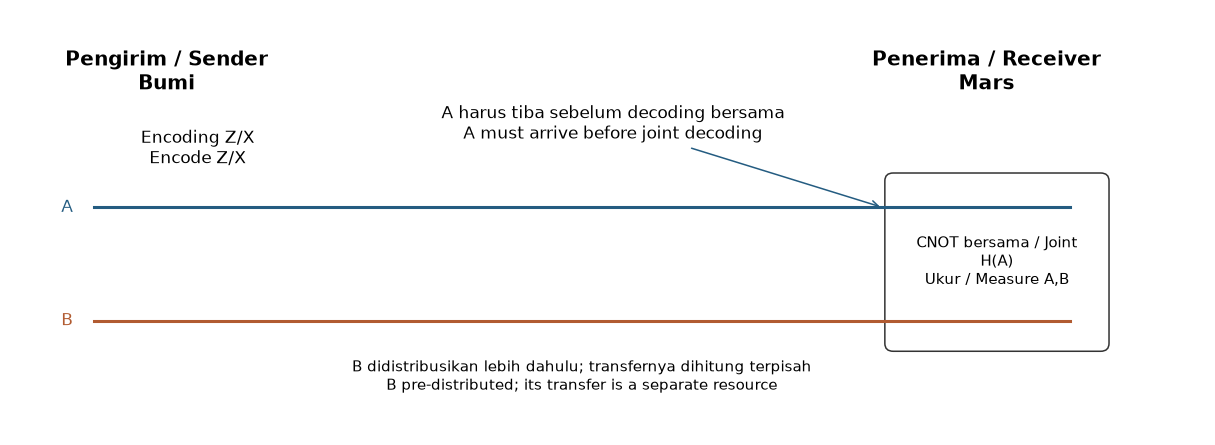

In [2]:
from scripts.notebook_support import ownership
fig = ownership()
save(fig, 'superdense_ownership')
display(fig); plt.close(fig)


**Bahasa Indonesia**

## 2. Circuit yang benar-benar digunakan aplikasi

Kode berikut mengimpor fungsi engine aktif. Gate dan hasil bukan diagram
dekoratif yang terpisah dari implementasi. Contoh z=x=1 dapat memiliki tanda
minus global pada akhir circuit tanpa mengubah hasil `11`.

---

**English**

## 2. The circuit actually used by the application

The following code imports the active engine functions. Gates and results are
part of the implementation, rather than a separate decorative diagram. The
z=x=1 example may end with a global minus sign without changing outcome `11`.


0: ───H───@───Z───X───@───H───M('received')───
          │           │       │
1: ───────X───────────X───────M───────────────


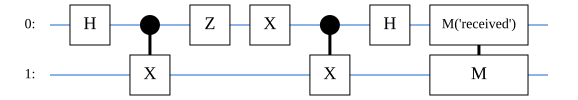

In [3]:
from densechat.quantum import encode_pair, transfer_qubit_a, joint_decode
from cirq.contrib.svg import SVGCircuit
A, B = cirq.LineQubit.range(2)
circuit = joint_decode(transfer_qubit_a(encode_pair(1, 1)))
print(circuit)
display(SVGCircuit(circuit))


**Bahasa Indonesia**

## 3. Verifikasi semua simbol

Setiap shot mempersiapkan Bell pair baru. Kami memakai `repetitions=1` per
run, menghindari interpretasi urutan keluaran sampler terminal multi-shot
sebagai urutan pengukuran lokal. Tabel di bawah dihitung oleh qsimcirq.

---

**English**

## 3. Verification of every symbol

Each shot prepares a fresh Bell pair. We use `repetitions=1` for each run,
avoiding interpreting a terminal multi-shot sampler's output order as the order
of local measurements. The table below is computed by qsimcirq.


In [4]:
symbol_rows = []
for z in (0, 1):
    for x in (0, 1):
        ideal = joint_decode(transfer_qubit_a(encode_pair(z, x)))
        simulator = qsimcirq.QSimSimulator(seed=SEED + 2*z + x, qsim_options={'t': 1})
        shots = [''.join(map(str, map(int, simulator.run(ideal, repetitions=1).measurements['received'][0]))) for _ in range(32)]
        expected = f'{z}{x}'
        assert all(result == expected for result in shots)
        symbol_rows.append({'masukan / input z,x': expected, 'shots': len(shots), 'correct': sum(s == expected for s in shots)})
display(bilingual_table(pd.DataFrame(symbol_rows)))


,"masukan / input z,x",shot / shots,benar / correct
0,00,32,32
1,01,32,32
2,10,32,32
3,11,32,32


**Bahasa Indonesia**

## 4. Mengapa B sendiri tidak membaca pilihan pengirim

Untuk semua empat encoding, $\rho_B=\operatorname{Tr}_A(|\psi\rangle\langle\psi|)=I/2$.
Karena itu $P(B=0)=P(B=1)=1/2$. Perubahan tanda relatif dapat mengubah
Bell state, tetapi tidak mengubah marginal B. Joint decoding membutuhkan A.
Perhitungan global berikut hanya merupakan **observer diagnostik**, bukan
data yang diberikan ke endpoint penerima chat.

---

**English**

## 4. Why B alone cannot read the sender's choice

For all four encodings, $\rho_B=\operatorname{Tr}_A(|\psi\rangle\langle\psi|)=I/2$.
Therefore $P(B=0)=P(B=1)=1/2$. Changing relative signs can change the Bell state
without changing B's marginal. Joint decoding requires A. The following global
calculation is a **diagnostic observer**, not data given to the chat receiver.


In [5]:
states, marginal_rows = [], []
for z in (0, 1):
    for x in (0, 1):
        prefix = cirq.Circuit(encode_pair(z, x).circuit)
        vector = qsimcirq.QSimSimulator(seed=SEED).simulate(prefix, qubit_order=[A, B]).final_state_vector.astype(complex)
        rho = np.outer(vector, vector.conj())
        rho_b = np.trace(rho.reshape(2,2,2,2), axis1=0, axis2=2)
        np.testing.assert_allclose(rho_b, np.eye(2)/2, atol=1e-6)
        states.append((f'{z}{x}', rho))
        marginal_rows.append({'input': f'{z}{x}', 'state': cirq.dirac_notation(vector, decimals=3),
                              'P(B=0)': rho_b[0,0].real, 'P(B=1)': rho_b[1,1].real})
display(bilingual_table(pd.DataFrame(marginal_rows)))


,masukan / input,state / keadaan,P(B=0),P(B=1)
0,00,0.707|00⟩ + 0.707|11⟩,0.5,0.5
1,01,0.707|01⟩ + 0.707|10⟩,0.5,0.5
2,10,0.707|00⟩ - 0.707|11⟩,0.5,0.5
3,11,-0.707|01⟩ + 0.707|10⟩,0.5,0.5


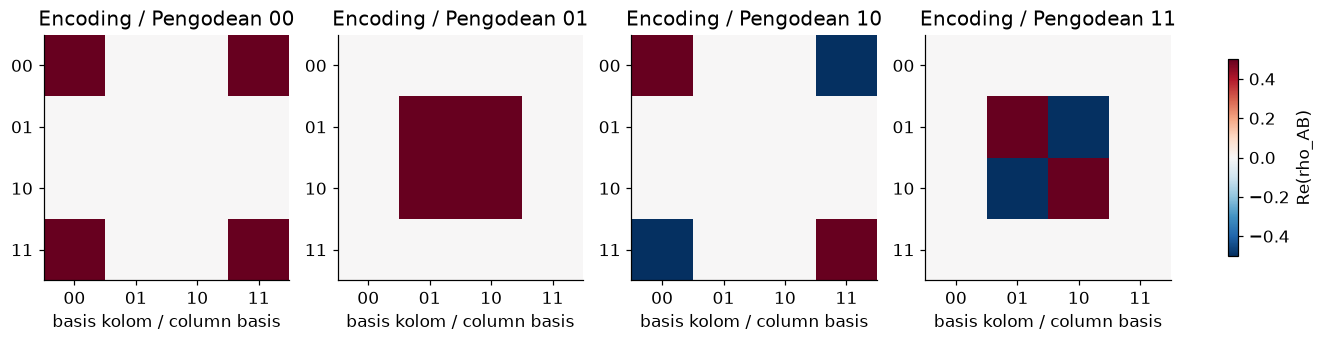

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3), constrained_layout=True)
for ax, (bits, rho) in zip(axes, states):
    image = ax.imshow(rho.real, vmin=-.5, vmax=.5, cmap='RdBu_r')
    ax.set(title=f'Encoding / Pengodean {bits}', xticks=range(4), yticks=range(4),
           xticklabels=['00','01','10','11'], yticklabels=['00','01','10','11'])
    ax.set_xlabel('basis kolom / column basis')
fig.colorbar(image, ax=axes, label='Re(rho_AB)', shrink=.8)
save(fig, 'bell_density_matrices')
display(fig); plt.close(fig)


**Bahasa Indonesia**

## 5. Interpretasi dan batas

Assertion empat simbol memeriksa mapping bit, sedangkan reduced-state check
memeriksa marginal ideal. Ini bukan pengujian hardware atau penemuan kanal
tanpa transfer. Satu pasangan memiliki dua qubit: biaya awal distribusi B
dan biaya pengiriman A perlu dinyatakan terpisah. Persamaan $I/2$ menjelaskan
mengapa lebih banyak sampel lokal B tidak menyediakan encoding pengirim.

Berikutnya: [notebook 02](02_quantum_chat_protocol.ipynb) menghubungkan simbol
dua bit menjadi frame teks, checksum, ACK dan biaya protokol.

---

**English**

## 5. Interpretation and limitations

The four-symbol assertions check the bit mapping; the reduced-state check tests
the ideal marginal. These are neither hardware tests nor discovery of a channel
without transfer. A pair contains two qubits: initial B distribution and later A
transmission must be counted separately. The I/2 equation explains why more local
B samples do not reveal the sender's encoding.

Next: [notebook 02](02_quantum_chat_protocol.ipynb) connects two-bit symbols to
text frames, checksums, ACKs, and protocol costs.


**Bahasa Indonesia**

## Referensi primer dan cara mengutip

1. C. H. Bennett & S. J. Wiesner (1992), *Communication via one- and two-particle
   operators on Einstein-Podolsky-Rosen states*, Physical Review Letters 69, 2881.
   [DOI: 10.1103/PhysRevLett.69.2881](https://doi.org/10.1103/PhysRevLett.69.2881).
2. [IBM Quantum Learning — superdense coding](https://quantum.cloud.ibm.com/learning/en/courses/basics-of-quantum-information/entanglement-in-action/superdense-coding).
3. [IBM Quantum Learning — reduced states](https://quantum.cloud.ibm.com/learning/en/courses/general-formulation-of-quantum-information/density-matrices/multiple-systems).
4. [Google Quantum AI — qsimcirq](https://quantumai.google/qsim/tutorials/qsimcirq),
   [DepolarizingChannel](https://quantumai.google/reference/python/cirq/DepolarizingChannel).

BibTeX ada pada [docs/references.bib](../docs/references.bib), metadata software
pada [CITATION.cff](../CITATION.cff). Tidak ada DOI software atau klaim peer-review.
Notebook ini merupakan penjelasan dan verifikasi numerik protokol yang sudah ada.

---

**English**

## Primary references and citation

1. C. H. Bennett & S. J. Wiesner (1992), *Communication via one- and two-particle
   operators on Einstein-Podolsky-Rosen states*, Physical Review Letters 69, 2881.
   [DOI: 10.1103/PhysRevLett.69.2881](https://doi.org/10.1103/PhysRevLett.69.2881).
2. [IBM Quantum Learning — superdense coding](https://quantum.cloud.ibm.com/learning/en/courses/basics-of-quantum-information/entanglement-in-action/superdense-coding).
3. [IBM Quantum Learning — reduced states](https://quantum.cloud.ibm.com/learning/en/courses/general-formulation-of-quantum-information/density-matrices/multiple-systems).
4. [Google Quantum AI — qsimcirq](https://quantumai.google/qsim/tutorials/qsimcirq),
   [DepolarizingChannel](https://quantumai.google/reference/python/cirq/DepolarizingChannel).

BibTeX is in [docs/references.bib](../docs/references.bib); software metadata is
in [CITATION.cff](../CITATION.cff). No software DOI or peer-review claim is made.
This notebook explains and numerically verifies an established protocol.
